# 03 — Top 5 District Scoring & Screening (Balanced Matching)

Mục tiêu: chọn **5 khu ưu tiên** từ đúng 19-area old-project universe theo 3 nhóm sếp yêu cầu: **hiện hữu iCare, đối thủ/thị trường, business fit**.

Nguyên tắc:
- Không dùng economic metrics thiếu comparability vào core score.
- Không dùng traffic evidence count như traffic volume.
- `icare_presence` là guardrail, không cộng ngang hàng với coverage distance/share.
- Ưu tiên **balanced_floor** để khu được chọn không quá yếu ở bất kỳ nhóm nào; `consensus_score` chỉ tie-break.


In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

raw_path = Path("../Data/Raw/Data_input.xlsx")
processed_path = Path("../Data/Processed/Data_processed.xlsx")
framework_candidates = [
    Path("../Data/Raw/Data_input_TOP5_FRAMEWORK_V3.xlsx"),
    raw_path,
    processed_path,
]

file_path = None
for p in framework_candidates:
    if p.exists():
        try:
            x = pd.ExcelFile(p)
            if "Top5_Scoring_Framework" in x.sheet_names:
                file_path = p
                break
        except Exception:
            pass

if file_path is None:
    raise FileNotFoundError(
        "Không tìm thấy workbook có sheet Top5_Scoring_Framework. "
        "Hãy chạy build_top5_framework_v3.py trước."
    )

print("Using:", file_path.resolve())


Using: D:\IcareWork\Place for icare\Data\Raw\Data_input_TOP5_FRAMEWORK_V3.xlsx


In [2]:
xls = pd.ExcelFile(file_path)
framework = pd.read_excel(file_path, sheet_name="Top5_Scoring_Framework")
definitions = pd.read_excel(file_path, sheet_name="Top5_Metric_Definition")

print("Rows:", len(framework))
print("Columns:", framework.columns.tolist())
display(framework.head())


Rows: 19
Columns: ['district_old', 'icare_presence', 'median_nearest_icare_km', 'uncovered_share_5km', 'competitor_locations', 'competitor_brands', 'population', 'density', 'traffic_evidence', 'enterprise_count', 'turnover', 'employee_compensation', 'coverage_status', 'core_available_n', 'core_required_n', 'core_complete_pct', 'economic_complete_n', 'data_status', 'source_trace', 'notes']


,district_old,icare_presence,median_nearest_icare_km,uncovered_share_5km,competitor_locations,competitor_brands,population,density,traffic_evidence,enterprise_count,turnover,employee_compensation,coverage_status,core_available_n,core_required_n,core_complete_pct,economic_complete_n,data_status,source_trace,notes
0,Thủ Đức,1,1.709840,0.285714,7,3,1225192,5790,1,33868.0,1132649.0,13.697,REQUIRED,8,8,1,3,CORE_READY_ECON_READY,GPS-derived 04 -> 06 -> 09_District_Opportunit...,"traffic_evidence = evidence breadth, KHÔNG phả..."
1,Tân Bình,1,1.734695,0.000000,6,4,502185,22389,2,16619.0,545162.0,16.057,REQUIRED,8,8,1,3,CORE_READY_ECON_READY,GPS-derived 04 -> 06 -> 09_District_Opportunit...,"traffic_evidence = evidence breadth, KHÔNG phả..."
2,Bình Thạnh,0,5.259363,0.500000,6,6,486494,23412,4,15694.0,541057.0,11.354,REQUIRED,8,8,1,3,CORE_READY_ECON_READY,GPS-derived 04 -> 06 -> 09_District_Opportunit...,"traffic_evidence = evidence breadth, KHÔNG phả..."
3,Quận 10,0,1.260782,0.000000,6,5,229046,40043,1,5838.0,207273.0,15.014,REQUIRED,8,8,1,3,CORE_READY_ECON_READY,GPS-derived 04 -> 06 -> 09_District_Opportunit...,"traffic_evidence = evidence breadth, KHÔNG phả..."
4,Quận 1,0,2.292305,0.000000,5,4,141722,18358,1,16922.0,2008597.0,18.382,REQUIRED,8,8,1,3,CORE_READY_ECON_READY,GPS-derived 04 -> 06 -> 09_District_Opportunit...,"traffic_evidence = evidence breadth, KHÔNG phả..."


## 1. Validate universe & completeness

Framework phải có đúng **19 khu**. Vũng Tàu và Bà Rịa có economic partial nhưng core 8/8; Quận 5 có coverage N/A hợp lệ vì không có observed competitor point.


In [3]:
EXPECTED_19 = [
    "Thủ Đức","Tân Bình","Bình Thạnh","Quận 10","Quận 1","Quận 12","Quận 7",
    "Bình Tân","Gò Vấp","Quận 3","Tân Phú","Dĩ An","Quận 4","Quận 6",
    "Thủ Dầu Một","Vũng Tàu","Bà Rịa","Phú Nhuận","Quận 5"
]

assert len(framework) == 19, f"Expected 19 rows, found {len(framework)}"
assert framework["district_old"].is_unique, "Duplicate district rows found."
assert set(framework["district_old"]) == set(EXPECTED_19), "Universe mismatch."

check_cols = [
    "district_old","core_available_n","core_required_n","core_complete_pct",
    "economic_complete_n","data_status","coverage_status"
]
display(framework[check_cols])

assert (framework["core_complete_pct"] == 1).all(),     "Core data chưa complete cho toàn universe."


,district_old,core_available_n,core_required_n,core_complete_pct,economic_complete_n,data_status,coverage_status
0,Thủ Đức,8,8,1,3,CORE_READY_ECON_READY,REQUIRED
1,Tân Bình,8,8,1,3,CORE_READY_ECON_READY,REQUIRED
2,Bình Thạnh,8,8,1,3,CORE_READY_ECON_READY,REQUIRED
3,Quận 10,8,8,1,3,CORE_READY_ECON_READY,REQUIRED
4,Quận 1,8,8,1,3,CORE_READY_ECON_READY,REQUIRED
5,Quận 12,8,8,1,3,CORE_READY_ECON_READY,REQUIRED
6,Quận 7,8,8,1,3,CORE_READY_ECON_READY,REQUIRED
7,Bình Tân,8,8,1,3,CORE_READY_ECON_READY,REQUIRED
8,Gò Vấp,8,8,1,3,CORE_READY_ECON_READY,REQUIRED
9,Quận 3,8,8,1,3,CORE_READY_ECON_READY,REQUIRED


## 2. Core metrics theo 3 nhóm sếp yêu cầu

### A. Hiện hữu iCare
- `median_nearest_icare_km`: cao hơn = observed coverage gap lớn hơn.
- `uncovered_share_5km`: cao hơn = nhiều observed market points nằm ngoài bán kính 5 km hơn.
- `icare_presence`: **không cộng trực tiếp vào group score**; dùng làm guardrail vì không có iCare trong ranh quận không đồng nghĩa khu đó chưa được iCare gần đó phục vụ.

### B. Đối thủ / thị trường
- `competitor_locations`
- `competitor_brands`

Hai biến này phản ánh **market activity quan sát được**, không phải demand/customer count.

### C. Business fit
- `population`
- `density`

`traffic_evidence` chỉ là evidence breadth / validation, **không phải traffic volume**.
Economic metrics chỉ dùng support/tie-break vì chưa comparable đủ 19 khu.


In [4]:
score = framework.copy()

core_numeric = [
    "icare_presence","median_nearest_icare_km","uncovered_share_5km",
    "competitor_locations","competitor_brands","population","density",
    "traffic_evidence","enterprise_count","turnover","employee_compensation"
]
for c in core_numeric:
    score[c] = pd.to_numeric(score[c], errors="coerce")

display(score[["district_old"] + core_numeric])


,district_old,icare_presence,median_nearest_icare_km,uncovered_share_5km,competitor_locations,competitor_brands,population,density,traffic_evidence,enterprise_count,turnover,employee_compensation
0,Thủ Đức,1,1.709840,0.285714,7,3,1225192,5790,1,33868.0,1132649.0,13.697
1,Tân Bình,1,1.734695,0.000000,6,4,502185,22389,2,16619.0,545162.0,16.057
2,Bình Thạnh,0,5.259363,0.500000,6,6,486494,23412,4,15694.0,541057.0,11.354
3,Quận 10,0,1.260782,0.000000,6,5,229046,40043,1,5838.0,207273.0,15.014
4,Quận 1,0,2.292305,0.000000,5,4,141722,18358,1,16922.0,2008597.0,18.382
5,Quận 12,0,8.767014,1.000000,4,3,731898,13877,4,14394.0,190993.0,10.709
6,Quận 7,0,4.718697,0.500000,4,3,356180,9980,3,10092.0,619079.0,16.699
7,Bình Tân,0,7.277906,1.000000,3,3,797906,15338,4,15418.0,291340.0,10.152
8,Gò Vấp,0,4.026249,0.000000,3,3,683654,34650,3,17012.0,259860.0,10.848
9,Quận 3,0,2.018315,0.000000,3,2,189931,38604,1,9465.0,518188.0,15.950


## 3. Percentile scoring 0–100

Cách tính:
- Metric “cao hơn tốt hơn” → percentile rank tăng dần.
- `icare_presence` đảo chiều: **chưa có iCare = 100**, đã có iCare = 0.
- Coverage metric N/A của Quận 5 **không đổi thành 0**.
- Group score = trung bình các metric **có dữ liệu hợp lệ** trong nhóm. Không đặt trọng số riêng.


In [5]:
def percentile_high(series):
    s = pd.to_numeric(series, errors="coerce")
    return s.rank(pct=True, method="average") * 100

# A — iCare coverage
# Presence vẫn tính riêng để xem/guardrail, nhưng KHÔNG đưa vào group score.
score["s_icare_presence"] = np.where(score["icare_presence"].eq(0), 100.0, 0.0)
score["s_coverage_distance"] = percentile_high(score["median_nearest_icare_km"])
score["s_uncovered_share"] = percentile_high(score["uncovered_share_5km"])

# B — Market
score["s_competitor_locations"] = percentile_high(score["competitor_locations"])
score["s_competitor_brands"] = percentile_high(score["competitor_brands"])

# C — Business
score["s_population"] = percentile_high(score["population"])
score["s_density"] = percentile_high(score["density"])

score_cols = [c for c in score.columns if c.startswith("s_")]
display(score[["district_old"] + score_cols])


,district_old,s_icare_presence,s_coverage_distance,s_uncovered_share,s_competitor_locations,s_competitor_brands,s_population,s_density
0,Thủ Đức,0.0,16.666667,50.000000,100.000000,65.789474,100.000000,21.052632
1,Tân Bình,0.0,22.222222,25.000000,89.473684,86.842105,73.684211,52.631579
2,Bình Thạnh,100.0,61.111111,58.333333,89.473684,100.000000,68.421053,57.894737
3,Quận 10,100.0,11.111111,25.000000,89.473684,94.736842,36.842105,94.736842
4,Quận 1,100.0,33.333333,25.000000,78.947368,86.842105,10.526316,47.368421
5,Quận 12,100.0,83.333333,83.333333,71.052632,65.789474,89.473684,36.842105
6,Quận 7,100.0,55.555556,58.333333,71.052632,65.789474,47.368421,31.578947
7,Bình Tân,100.0,77.777778,83.333333,55.263158,65.789474,94.736842,42.105263
8,Gò Vấp,100.0,50.000000,25.000000,55.263158,65.789474,84.210526,84.210526
9,Quận 3,100.0,27.777778,25.000000,55.263158,34.210526,31.578947,89.473684


In [6]:
# Nhóm A chỉ dùng coverage thực tế quan sát được, không cộng icare_presence.
icare_metric_scores = ["s_coverage_distance", "s_uncovered_share"]
market_metric_scores = ["s_competitor_locations", "s_competitor_brands"]
business_metric_scores = ["s_population", "s_density"]

score["icare_group_score"] = score[icare_metric_scores].mean(axis=1, skipna=True)
score["market_group_score"] = score[market_metric_scores].mean(axis=1, skipna=True)
score["business_group_score"] = score[business_metric_scores].mean(axis=1, skipna=True)

# Consensus = trung bình 3 nhóm, chỉ dùng secondary/tie-break.
score["consensus_score"] = score[[
    "icare_group_score", "market_group_score", "business_group_score"
]].mean(axis=1)

# Balanced floor = nhóm yếu nhất. Đây là tiêu chí chính để tránh 1 nhóm quá mạnh bù nhóm quá yếu.
score["balanced_floor"] = score[[
    "icare_group_score", "market_group_score", "business_group_score"
]].min(axis=1)

display(score[[
    "district_old", "icare_group_score", "market_group_score",
    "business_group_score", "balanced_floor", "consensus_score"
]].sort_values(["balanced_floor", "consensus_score"], ascending=[False, False]))


,district_old,icare_group_score,market_group_score,business_group_score,balanced_floor,consensus_score
5,Quận 12,83.333333,68.421053,63.157895,63.157895,71.637427
7,Bình Tân,80.555556,60.526316,68.421053,60.526316,69.834308
2,Bình Thạnh,59.722222,94.736842,63.157895,59.722222,72.538986
6,Quận 7,56.944444,68.421053,39.473684,39.473684,54.946394
8,Gò Vấp,37.500000,60.526316,84.210526,37.500000,60.745614
10,Tân Phú,34.722222,60.526316,63.157895,34.722222,52.802144
0,Thủ Đức,33.333333,82.894737,60.526316,33.333333,58.918129
11,Dĩ An,77.777778,32.894737,52.631579,32.894737,54.434698
13,Quận 6,75.000000,32.894737,55.263158,32.894737,54.385965
15,Vũng Tàu,91.666667,32.894737,34.210526,32.894737,52.923977


## 4. Rank theo từng nhóm — ưu tiên cân bằng

Không chọn khu chỉ vì một nhóm có điểm rất cao. `balanced_floor` (điểm thấp nhất trong 3 nhóm) là tiêu chí chính; `consensus_score` chỉ dùng để tie-break.


In [7]:
for c, out in [
    ("icare_group_score", "rank_icare"),
    ("market_group_score", "rank_market"),
    ("business_group_score", "rank_business"),
    ("balanced_floor", "rank_balanced_floor"),
    ("consensus_score", "rank_consensus"),
]:
    score[out] = score[c].rank(ascending=False, method="min")

rank_view = score[[
    "district_old",
    "icare_group_score", "rank_icare",
    "market_group_score", "rank_market",
    "business_group_score", "rank_business",
    "balanced_floor", "rank_balanced_floor",
    "consensus_score", "rank_consensus",
]].sort_values(["rank_balanced_floor", "rank_consensus", "district_old"])

display(rank_view)


,district_old,icare_group_score,rank_icare,market_group_score,rank_market,business_group_score,rank_business,balanced_floor,rank_balanced_floor,consensus_score,rank_consensus
5,Quận 12,83.333333,4.0,68.421053,6.0,63.157895,5.0,63.157895,1.0,71.637427,2.0
7,Bình Tân,80.555556,5.0,60.526316,8.0,68.421053,2.0,60.526316,2.0,69.834308,3.0
2,Bình Thạnh,59.722222,8.0,94.736842,1.0,63.157895,4.0,59.722222,3.0,72.538986,1.0
6,Quận 7,56.944444,9.0,68.421053,6.0,39.473684,15.0,39.473684,4.0,54.946394,8.0
8,Gò Vấp,37.500000,10.0,60.526316,8.0,84.210526,1.0,37.500000,5.0,60.745614,4.0
10,Tân Phú,34.722222,11.0,60.526316,8.0,63.157895,5.0,34.722222,6.0,52.802144,12.0
0,Thủ Đức,33.333333,12.0,82.894737,4.0,60.526316,9.0,33.333333,7.0,58.918129,5.0
11,Dĩ An,77.777778,6.0,32.894737,12.0,52.631579,12.0,32.894737,8.0,54.434698,9.0
13,Quận 6,75.000000,7.0,32.894737,12.0,55.263158,11.0,32.894737,8.0,54.385965,10.0
15,Vũng Tàu,91.666667,1.0,32.894737,12.0,34.210526,16.0,32.894737,8.0,52.923977,11.0


## 5. Pareto trên 3 group scores

Một khu nằm Pareto front nếu không có khu khác tốt hơn hoặc bằng nó ở cả 3 nhóm và tốt hơn ít nhất một nhóm. Đây là lớp kiểm tra để tránh Top 5 bị quyết định chỉ bởi điểm trung bình.


In [8]:
def pareto_flags(df, metrics):
    work = df[["district_old"] + metrics].dropna().copy().reset_index(drop=True)
    X = work[metrics].to_numpy(float)
    dominated_by_count = np.zeros(len(work), dtype=int)
    dominates_count = np.zeros(len(work), dtype=int)

    for i in range(len(work)):
        for j in range(len(work)):
            if i == j:
                continue
            if np.all(X[j] >= X[i]) and np.any(X[j] > X[i]):
                dominated_by_count[i] += 1
            if np.all(X[i] >= X[j]) and np.any(X[i] > X[j]):
                dominates_count[i] += 1

    work["pareto_3group"] = dominated_by_count == 0
    work["dominated_by_count"] = dominated_by_count
    work["dominates_count"] = dominates_count
    return work

pareto3 = pareto_flags(score, [
    "icare_group_score","market_group_score","business_group_score"
])
score = score.merge(pareto3[[
    "district_old","pareto_3group","dominated_by_count","dominates_count"
]], on="district_old", how="left")

display(score[[
    "district_old","icare_group_score","market_group_score","business_group_score",
    "pareto_3group","dominated_by_count","dominates_count","consensus_score"
]].sort_values(["pareto_3group","consensus_score"], ascending=[False,False]))


,district_old,icare_group_score,market_group_score,business_group_score,pareto_3group,dominated_by_count,dominates_count,consensus_score
2,Bình Thạnh,59.722222,94.736842,63.157895,True,0.0,8.0,72.538986
5,Quận 12,83.333333,68.421053,63.157895,True,0.0,7.0,71.637427
7,Bình Tân,80.555556,60.526316,68.421053,True,0.0,6.0,69.834308
8,Gò Vấp,37.500000,60.526316,84.210526,True,0.0,4.0,60.745614
3,Quận 10,18.055556,92.105263,65.789474,True,0.0,1.0,58.650097
15,Vũng Tàu,91.666667,32.894737,34.210526,True,0.0,2.0,52.923977
0,Thủ Đức,33.333333,82.894737,60.526316,False,1.0,3.0,58.918129
1,Tân Bình,23.611111,88.157895,63.157895,False,1.0,1.0,58.308967
6,Quận 7,56.944444,68.421053,39.473684,False,2.0,0.0,54.946394
11,Dĩ An,77.777778,32.894737,52.631579,False,2.0,1.0,54.434698


## 6. Guardrails trước khi chốt Top 5

- `icare_presence == 0`: ưu tiên khu chưa có iCare trực tiếp; đây là guardrail expansion, không cộng điểm.
- `competitor_locations > 0`: phải có observed market activity.
- `traffic_evidence > 0`: phải có ít nhất một traffic/context evidence; đây là validation, không phải traffic volume.
- `core_complete_pct == 1`: core data phải đủ.

Pareto vẫn được giữ để giải thích trade-off nhưng **không override balanced ranking**.


In [9]:
score["traffic_guardrail"] = np.where(
    score["traffic_evidence"].fillna(0) > 0,
    "TRAFFIC_EVIDENCE_PRESENT",
    "NO_TRAFFIC_EVIDENCE"
)
score["market_guardrail"] = np.where(
    score["competitor_locations"].fillna(0) > 0,
    "OBSERVED_MARKET_ACTIVITY",
    "NO_OBSERVED_COMPETITOR_ACTIVITY"
)
score["icare_guardrail"] = np.where(
    score["icare_presence"].eq(1),
    "DIRECT_ICARE_PRESENT",
    "NO_DIRECT_ICARE"
)

display(score[[
    "district_old","traffic_guardrail","market_guardrail","icare_guardrail",
    "coverage_status","data_status"
]])


,district_old,traffic_guardrail,market_guardrail,icare_guardrail,coverage_status,data_status
0,Thủ Đức,TRAFFIC_EVIDENCE_PRESENT,OBSERVED_MARKET_ACTIVITY,DIRECT_ICARE_PRESENT,REQUIRED,CORE_READY_ECON_READY
1,Tân Bình,TRAFFIC_EVIDENCE_PRESENT,OBSERVED_MARKET_ACTIVITY,DIRECT_ICARE_PRESENT,REQUIRED,CORE_READY_ECON_READY
2,Bình Thạnh,TRAFFIC_EVIDENCE_PRESENT,OBSERVED_MARKET_ACTIVITY,NO_DIRECT_ICARE,REQUIRED,CORE_READY_ECON_READY
3,Quận 10,TRAFFIC_EVIDENCE_PRESENT,OBSERVED_MARKET_ACTIVITY,NO_DIRECT_ICARE,REQUIRED,CORE_READY_ECON_READY
4,Quận 1,TRAFFIC_EVIDENCE_PRESENT,OBSERVED_MARKET_ACTIVITY,NO_DIRECT_ICARE,REQUIRED,CORE_READY_ECON_READY
5,Quận 12,TRAFFIC_EVIDENCE_PRESENT,OBSERVED_MARKET_ACTIVITY,NO_DIRECT_ICARE,REQUIRED,CORE_READY_ECON_READY
6,Quận 7,TRAFFIC_EVIDENCE_PRESENT,OBSERVED_MARKET_ACTIVITY,NO_DIRECT_ICARE,REQUIRED,CORE_READY_ECON_READY
7,Bình Tân,TRAFFIC_EVIDENCE_PRESENT,OBSERVED_MARKET_ACTIVITY,NO_DIRECT_ICARE,REQUIRED,CORE_READY_ECON_READY
8,Gò Vấp,TRAFFIC_EVIDENCE_PRESENT,OBSERVED_MARKET_ACTIVITY,NO_DIRECT_ICARE,REQUIRED,CORE_READY_ECON_READY
9,Quận 3,TRAFFIC_EVIDENCE_PRESENT,OBSERVED_MARKET_ACTIVITY,NO_DIRECT_ICARE,REQUIRED,CORE_READY_ECON_READY


## 7. Chọn Top 5

Rule chốt:
1. Core data complete.
2. Chưa có iCare trực tiếp trong khu.
3. Có observed competitor market activity.
4. Có traffic evidence để validation.
5. Rank **balanced_floor giảm dần**; `consensus_score` là tie-break; sau đó dùng `dominates_count`.

Cách này bám đúng yêu cầu “matching 3 yếu tố”: một khu phải tương đối ổn ở cả iCare coverage, market và business fit.


In [10]:
eligible = score[
    score["data_status"].str.startswith("CORE_READY", na=False)
    & score["icare_guardrail"].eq("NO_DIRECT_ICARE")
    & score["market_guardrail"].eq("OBSERVED_MARKET_ACTIVITY")
    & score["traffic_guardrail"].eq("TRAFFIC_EVIDENCE_PRESENT")
    & score["core_complete_pct"].eq(1)
].copy()

eligible = eligible.sort_values(
    ["balanced_floor", "consensus_score", "dominates_count"],
    ascending=[False, False, False]
).reset_index(drop=True)

eligible["top5_rank"] = np.arange(1, len(eligible) + 1)
top5 = eligible.head(5).copy()

print("=== TOP 5 DISTRICTS — BALANCED MATCHING ===")
display(top5[[
    "top5_rank", "district_old",
    "icare_group_score", "market_group_score", "business_group_score",
    "balanced_floor", "consensus_score", "pareto_3group",
    "icare_guardrail", "traffic_guardrail"
]])


=== TOP 5 DISTRICTS — BALANCED MATCHING ===


,top5_rank,district_old,icare_group_score,market_group_score,business_group_score,balanced_floor,consensus_score,pareto_3group,icare_guardrail,traffic_guardrail
0,1,Quận 12,83.333333,68.421053,63.157895,63.157895,71.637427,True,NO_DIRECT_ICARE,TRAFFIC_EVIDENCE_PRESENT
1,2,Bình Tân,80.555556,60.526316,68.421053,60.526316,69.834308,True,NO_DIRECT_ICARE,TRAFFIC_EVIDENCE_PRESENT
2,3,Bình Thạnh,59.722222,94.736842,63.157895,59.722222,72.538986,True,NO_DIRECT_ICARE,TRAFFIC_EVIDENCE_PRESENT
3,4,Quận 7,56.944444,68.421053,39.473684,39.473684,54.946394,False,NO_DIRECT_ICARE,TRAFFIC_EVIDENCE_PRESENT
4,5,Gò Vấp,37.500000,60.526316,84.210526,37.500000,60.745614,True,NO_DIRECT_ICARE,TRAFFIC_EVIDENCE_PRESENT


## 8. Lý do chọn từng khu

Sinh tự động từ raw metrics + group scores để dùng khi báo cáo sếp.


In [11]:
def reason_text(row):
    parts = []
    parts.append("chưa có iCare trực tiếp")

    if pd.notna(row["median_nearest_icare_km"]):
        parts.append(f"median nearest iCare {row['median_nearest_icare_km']:.2f} km")
    if pd.notna(row["uncovered_share_5km"]):
        parts.append(f"{row['uncovered_share_5km']:.0%} observed market points ngoài 5 km")

    parts.append(f"{int(row['competitor_locations'])} competitor locations / {int(row['competitor_brands'])} brands")
    parts.append(f"population {int(row['population']):,}")
    parts.append(f"density {int(row['density']):,}/km²")
    parts.append(f"balanced floor {row['balanced_floor']:.1f}/100")
    parts.append(f"3-group consensus {row['consensus_score']:.1f}/100")
    return "; ".join(parts)

top5["selection_reason"] = top5.apply(reason_text, axis=1)
display(top5[["top5_rank", "district_old", "selection_reason"]])


,top5_rank,district_old,selection_reason
0,1,Quận 12,chưa có iCare trực tiếp; median nearest iCare ...
1,2,Bình Tân,chưa có iCare trực tiếp; median nearest iCare ...
2,3,Bình Thạnh,chưa có iCare trực tiếp; median nearest iCare ...
3,4,Quận 7,chưa có iCare trực tiếp; median nearest iCare ...
4,5,Gò Vấp,chưa có iCare trực tiếp; median nearest iCare ...


## 9. Economic context — support only

Không đưa vào core score vì Vũng Tàu và Bà Rịa chưa có bộ 3 economic metrics comparable. Dùng để đọc thêm trade-off hoặc tie-break khi cần.


In [12]:
econ_view = score[[
    "district_old","enterprise_count","turnover","employee_compensation",
    "economic_complete_n","data_status"
]].copy()
display(econ_view.sort_values("enterprise_count", ascending=False, na_position="last"))


,district_old,enterprise_count,turnover,employee_compensation,economic_complete_n,data_status
0,Thủ Đức,33868.0,1132649.0,13.697,3,CORE_READY_ECON_READY
8,Gò Vấp,17012.0,259860.0,10.848,3,CORE_READY_ECON_READY
4,Quận 1,16922.0,2008597.0,18.382,3,CORE_READY_ECON_READY
1,Tân Bình,16619.0,545162.0,16.057,3,CORE_READY_ECON_READY
2,Bình Thạnh,15694.0,541057.0,11.354,3,CORE_READY_ECON_READY
7,Bình Tân,15418.0,291340.0,10.152,3,CORE_READY_ECON_READY
5,Quận 12,14394.0,190993.0,10.709,3,CORE_READY_ECON_READY
10,Tân Phú,13935.0,281002.0,11.131,3,CORE_READY_ECON_READY
6,Quận 7,10092.0,619079.0,16.699,3,CORE_READY_ECON_READY
9,Quận 3,9465.0,518188.0,15.950,3,CORE_READY_ECON_READY


## 10. Traffic context — validation only


In [13]:
traffic_view = score[[
    "district_old","traffic_evidence","traffic_guardrail"
]].sort_values("traffic_evidence", ascending=False)
display(traffic_view)


,district_old,traffic_evidence,traffic_guardrail
2,Bình Thạnh,4,TRAFFIC_EVIDENCE_PRESENT
7,Bình Tân,4,TRAFFIC_EVIDENCE_PRESENT
5,Quận 12,4,TRAFFIC_EVIDENCE_PRESENT
8,Gò Vấp,3,TRAFFIC_EVIDENCE_PRESENT
6,Quận 7,3,TRAFFIC_EVIDENCE_PRESENT
10,Tân Phú,2,TRAFFIC_EVIDENCE_PRESENT
1,Tân Bình,2,TRAFFIC_EVIDENCE_PRESENT
13,Quận 6,2,TRAFFIC_EVIDENCE_PRESENT
11,Dĩ An,2,TRAFFIC_EVIDENCE_PRESENT
0,Thủ Đức,1,TRAFFIC_EVIDENCE_PRESENT


## 11. Visualization — 3 group scores của Top 5

Chart này chỉ trực quan hóa 3 nhóm score. Thứ tự Top 5 vẫn theo `balanced_floor` trước, `consensus_score` sau.


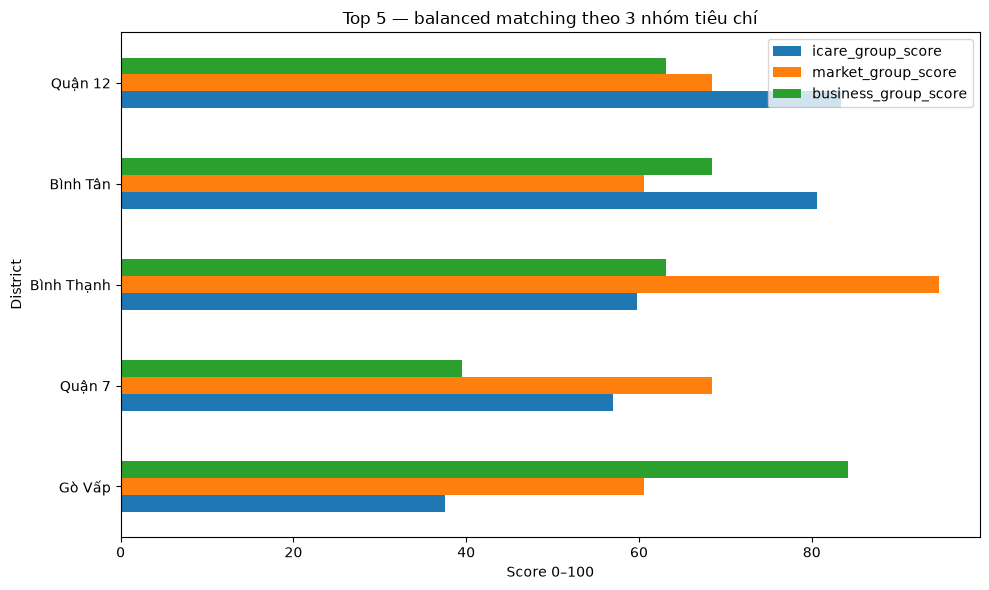

In [14]:
sort_col = "balanced_floor"

plot = (
    top5
    .sort_values([sort_col, "consensus_score"], ascending=[True, True])
    .set_index("district_old")[[
        "icare_group_score", "market_group_score", "business_group_score"
    ]]
)

ax = plot.plot(kind="barh", figsize=(10, 6))
ax.set_xlabel("Score 0–100")
ax.set_ylabel("District")
ax.set_title("Top 5 — balanced matching theo 3 nhóm tiêu chí")
plt.tight_layout()
plt.show()


## 12. Export EDA outputs


In [15]:
output_dir = Path("../Data/Processed")
output_dir.mkdir(parents=True, exist_ok=True)
out_path = output_dir / "District_Screening_EDA.xlsx"

with pd.ExcelWriter(out_path, engine="openpyxl") as writer:
    framework.to_excel(writer, sheet_name="01_Framework", index=False)
    score.to_excel(writer, sheet_name="02_All_Scored", index=False)
    rank_view.to_excel(writer, sheet_name="03_Group_Ranks", index=False)
    pareto3.to_excel(writer, sheet_name="04_Pareto_3Group", index=False)
    eligible.to_excel(writer, sheet_name="05_Eligible", index=False)
    top5.to_excel(writer, sheet_name="06_Top5", index=False)
    econ_view.to_excel(writer, sheet_name="07_Econ_Support", index=False)
    traffic_view.to_excel(writer, sheet_name="08_Traffic_Context", index=False)
    definitions.to_excel(writer, sheet_name="09_Metric_Definition", index=False)

print("Saved:", out_path.resolve())


Saved: D:\IcareWork\Place for icare\Data\Processed\District_Screening_EDA.xlsx
